# Solutions: what changed, and when?

Write the two functions from lecture, `log_evidence` and `log_bf`, then use them. The robot is in
`robot.py`. Needs `pip install matplotlib`; run from the repo root.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../..') if os.getcwd().endswith('changes') else os.getcwd())
import numpy as np
import matplotlib.pyplot as plt
from adaptation import BayesianLinearRegression
from labs.changes.robot import SIGMA, WORLDS, stream, closed_form_evidence

TAU = 1.     # prior SD of a change


def gauss_logpdf(y, mean, sd):
    return np.sum(-.5*((y - mean)/sd)**2 - np.log(sd) - .5*np.log(2*np.pi), -1)


def blr(n_features, n_outputs=1):
    return BayesianLinearRegression(n_features, n_outputs, prior_std=TAU, noise_std=SIGMA)

## 1. Evidence

Score each point with the model's predictive *before* it learns that point. The sum is the log evidence.

In [2]:
def log_evidence(model, X, y):
    """Log predictive density of each row of y (scored before learning it); model learns X, y as it goes."""
    out = []
    for x, yt in zip(X, y):
        mean, sd = model.predict(x, return_std=True)
        out.append(gauss_logpdf(yt, mean, sd))
        model.partial_fit(x[None], yt[None])
    return np.array(out)


a, y, r = stream(WORLDS['swap'])
X, y0 = a[100:130], r[100:130, :1]
print(log_evidence(blr(2), X, y0).sum(), closed_form_evidence(X, y0[:, 0], TAU))   # should match

-8.026444114157062 -8.026444114157087


## 2. What changed?

- **S0, nothing changed:** `r = noise`.
- **S1, motor strengths:** output i uses feature `a_i` only, so one 1-feature BLR per motor.
- **S2, wires mixed:** both outputs use features `a`, so one BLR with 2 features and 2 outputs.

The plot shows the posterior over S0, S1, S2 (equal prior) during the 30 steps after the change.

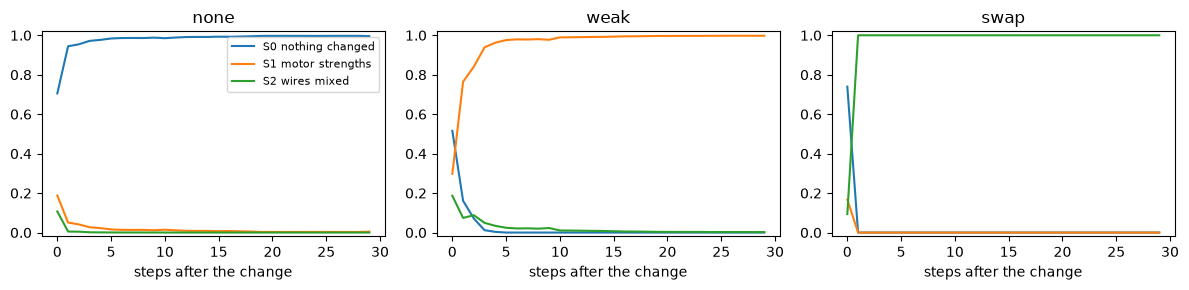

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, M) in zip(axs, WORLDS.items()):
    a, y, r = stream(M)
    a, r = a[100:130], r[100:130]
    s0 = gauss_logpdf(r, 0, SIGMA)
    s1 = log_evidence(blr(1), a[:, :1], r[:, :1]) + log_evidence(blr(1), a[:, 1:], r[:, 1:])
    s2 = log_evidence(blr(2, 2), a, r)
    E = np.cumsum(np.stack([s0, s1, s2], 1), 0)
    P = np.exp(E - E.max(1, keepdims=True))
    P /= P.sum(1, keepdims=True)
    ax.plot(P, label=['S0 nothing changed', 'S1 motor strengths', 'S2 wires mixed'])
    ax.set(title=name, xlabel='steps after the change', ylim=(-.02, 1.02))
axs[0].legend(fontsize=8); fig.tight_layout()

## 3. When did it change?

Test each candidate step s: do the next L steps fit a fresh model better than the model of the W steps
before s? Declare a change when log BF exceeds log((1 - h)/h).

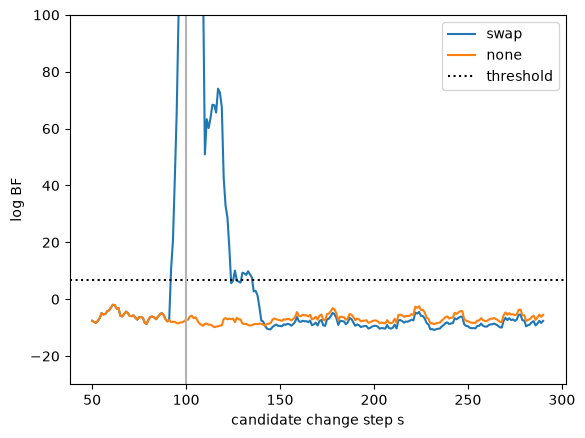

In [4]:
def log_bf(X_old, y_old, X_new, y_new):
    """log p(new | fresh model) - log p(new | model fitted on old), using the S2 model."""
    old = blr(2, 2).partial_fit(X_old, y_old)
    return log_evidence(blr(2, 2), X_new, y_new).sum() - log_evidence(old, X_new, y_new).sum()


def scan(a, r, W=50, L=10):
    """log BF for every candidate change step s."""
    return {s: log_bf(a[s - W:s], r[s - W:s], a[s:s + L], r[s:s + L]) for s in range(W, len(a) - L + 1)}


h = 1e-3
for name in ('swap', 'none'):
    bf = scan(*stream(WORLDS[name])[::2])
    plt.plot(list(bf), list(bf.values()), label=name)
plt.axhline(np.log((1 - h)/h), color='k', ls=':', label='threshold')
plt.axvline(100, color='0.7')
plt.ylim(-30, 100); plt.xlabel('candidate change step s'); plt.ylabel('log BF'); plt.legend();

## 4. The hazard bounds false alarms

With no change, each test fires with probability at most h/(1 - h).

In [5]:
for h in (1e-1, 1e-2, 1e-3):
    bf = np.concatenate([list(scan(*stream(np.eye(2), T=1000, change=1000, seed=k)[::2]).values()) for k in range(3)])
    rate = np.mean(bf > np.log((1 - h)/h))
    print(f'h = {h}: false alarms per test {rate:.4f}, bound {h/(1 - h):.4f}')

h = 0.1: false alarms per test 0.0007, bound 0.1111
h = 0.01: false alarms per test 0.0000, bound 0.0101
h = 0.001: false alarms per test 0.0000, bound 0.0010


## 5. Explore

How small a change can you detect? Vary the motor gain `g` and the window `L`. Then try the no-change
stream with `outliers=0.01` in part 4: what happens to the bound?

In [6]:
g, L = .7, 10
found = [any(v > np.log(999) for s, v in scan(*stream(np.diag([g, g]), seed=k)[::2], L=L).items() if 70 <= s <= 130)
         for k in range(8)]
print(f'gain {g}, L = {L}: detected in {sum(found)}/8 runs')

gain 0.7, L = 10: detected in 1/8 runs
